In [10]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import smarts_cerebellum.globals as gl

lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', 'patients_MNISymC_FaMap_CST_lme.tsv'), sep = '\t')
lme['Week'] = lme['Week'].astype(int)
lme = lme.sort_values('Week')

obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
obs = obs[obs.regionname == 'CST_R']

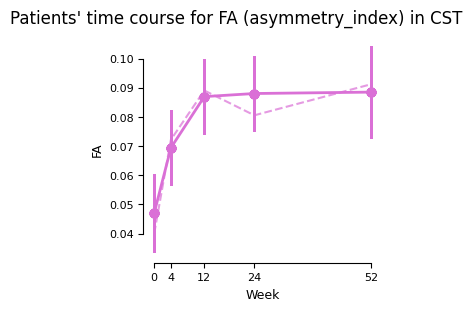

In [11]:
fig, ax = plt.subplots(figsize=(3,3), sharey = True, constrained_layout=True)

lme_ai = lme[(lme.regionname == 'CST_ai')].sort_values('Week')

obs_ai = obs[obs.regionname == 'CST_R'].groupby('Week')['asymmetry_index'].mean().reset_index()

ax.errorbar(x = lme_ai['Week'], y = lme_ai['beta'], yerr = lme_ai['se'], fmt = '-o', linewidth = 2, color = 'orchid')
ax.plot(obs_ai['Week'], obs_ai['asymmetry_index'], alpha = .7, linestyle = '--', color = 'orchid')


ax.set_xticks(gl.weeks)
ax.set_ylabel("FA")
ax.set_xlabel("Week")

plt.suptitle(f"Patients' time course for FA (asymmetry_index) in CST")
sns.despine(trim = True)
plt.show()

In [12]:
print(f'---t-test against 0 for asymmetry index of FA in CST (patients)--- \n')

for week in obs.Week.unique():
    t_val, p_val = stats.ttest_1samp(obs[(obs.Week == week)&(obs.regionname == 'CST_R')]['asymmetry_index'], popmean = 0)
    print(f'Week {week}: t-value = {t_val}, p-value = {p_val} \n')
    

---t-test against 0 for asymmetry index of FA in CST (patients)--- 

Week 0: t-value = 2.9414310951974736, p-value = 0.013413373075164135 

Week 4: t-value = 5.621987578699136, p-value = 4.8624984899663643e-05 

Week 12: t-value = 5.340878693394992, p-value = 6.62542052191208e-05 

Week 24: t-value = 5.527153045496359, p-value = 7.45258778882147e-05 

Week 52: t-value = 4.649609974415102, p-value = 0.005584087774483403 

